# Big Data Bowl 2027 — Injury Projection, the Combine, and the Case for Repeated Reps

**The argument, in five steps**

1. **Injury projection is the most valuable thing a scout could have.** Injuries are common for rookies, cost games at every draft slot, and hit the most expensive picks as often as anyone.
2. **The Combine, as it exists, can't provide it.** A full sweep of what the Combine measures (timed results and tracked drill movement) against rookie injury, and of how reliably it measures movement at all.
3. **Game tracking shows where injury risk is visible.** An in-season injury-risk model, built from game tracking and tested on seasons it never saw.
4. **More reps make measurement better, and better measurement makes injury prediction better.** Tested directly in game data, where players have hundreds of reps, plus the theory that ties reliability to prediction.
5. **A Combine drill for each position group,** chosen from the data: the existing drill that measures each group's key trait most reliably, and how many tracked reps it needs.

**What counts as evidence here:** results that don't involve injury outcomes (reliability) can be definitive. Injury results are labeled by strength: pre-specified, exploratory, or theoretical. Tests for Step 3 and Step 4 were recorded in the findings doc before running.

**Runs on:** `bdb_core.py` (same folder) and the data in `../data/` plus nflverse. It reuses saved caches in `outputs/cache/` (and older ones in `outputs/cross_position/`); anything missing is rebuilt from tracking on the first run, which is slow. Without `../data/`, it runs on synthetic data from `synthetic/`.

**Outputs:** tables and figures in `outputs/main/`; the last cell prints everything to send back.

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import bdb_core as bc

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

OUT = Path("outputs/main")
OUT.mkdir(parents=True, exist_ok=True)
SEED = 0
rng = np.random.default_rng(SEED)
N_BOOT, N_PERM = 300, 200
FAMILY_KEYS = ["db", "receivers", "ol", "edge", "idl"]      # set to ["db"] for a quick run
GROUP_OF = {k: bc.FAMILIES[k]["label"] for k in FAMILY_KEYS}

P = bc.Project()
RK = P.rookies()
ATT = P.combine_attempts()
TIMED = P.timed
print(RK.groupby("group").agg(players=("nfl_id", "size"), injured=("injured", "sum")).to_string())


def save(df, name):
    df.to_csv(OUT / f"{name}.csv", index=False)
    return df


def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / f"{name}.png", dpi=170); plt.show()

Real data from C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data
             players  injured
group                        
DB               118       24
Edge              66        8
Interior DL       52        8
OL               121       21
Receivers        148       38


## Step 1. Why injury projection matters to a scout

A scout's job is to predict what a player will give a team. Talent only pays off on the field, and injuries take players off it. Three things from the data make the case:
- **How often rookies get hurt,** and how many games they miss when they do.
- **Who gets hurt:** if high picks are injured as often as late picks, injury risk is a direct threat to a team's largest investments.
- **What follows:** how much playing time injured rookies lose, against comparable rookies who stayed healthy.

Rookies here are the 2023–2025 draft classes. "Injured" means at least one game missed with an injury in the draft-year season (weeks listed Out, plus 3+ game absences right after an injury listing, which catches injured reserve).

,measure,value
0,"Rookies (all 510 drafted players, 5 position g...",505.000
1,Share injured as rookies (all),0.196
2,Share injured among rookies who played 4+ games,0.251
3,Games missed per injured rookie (mean),3.414
4,Games missed per injured rookie (median),3.000
5,Injured rookies missing 4+ games,0.323
6,Total rookie games lost to injury,338.000


,round_group,players,injured_share,injured_share_4plus_games,mean_games_missed_if_injured
0,Round 1,38,0.211,0.189,4.125
1,Rounds 2–3,118,0.314,0.310,3.730
2,Rounds 4–5,118,0.212,0.229,3.680
3,Rounds 6–7,105,0.190,0.230,3.000
4,Undrafted,126,0.071,0.229,1.667


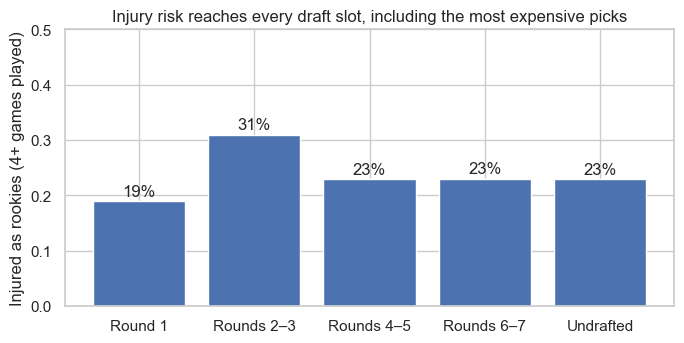

In [2]:
played = RK[RK.games_played >= bc.MIN_GAMES]
inj = RK[RK.injured]
S1 = pd.DataFrame([
    dict(measure="Rookies (all 510 drafted players, 5 position groups)", value=len(RK)),
    dict(measure="Share injured as rookies (all)", value=RK.injured.mean()),
    dict(measure="Share injured among rookies who played 4+ games", value=played.injured.mean()),
    dict(measure="Games missed per injured rookie (mean)", value=inj.games_out.mean()),
    dict(measure="Games missed per injured rookie (median)", value=inj.games_out.median()),
    dict(measure="Injured rookies missing 4+ games", value=(inj.games_out >= 4).mean()),
    dict(measure="Total rookie games lost to injury", value=inj.games_out.sum()),
])
display(save(S1, "S1_burden").round(3))

by_round = (RK.assign(round_group=pd.cut(RK.draft_round, [0, 1, 3, 5, 7, 9], labels=["Round 1", "Rounds 2–3", "Rounds 4–5", "Rounds 6–7", "Undrafted"]))
              .groupby("round_group", observed=True)
              .agg(players=("nfl_id", "size"), injured_share=("injured", "mean"),
                   injured_share_4plus_games=("injured", lambda s: s[RK.loc[s.index, "games_played"] >= bc.MIN_GAMES].mean()),
                   mean_games_missed_if_injured=("games_out", lambda s: s[s > 0].mean())).reset_index())
display(save(by_round, "S1_by_round").round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(by_round.round_group.astype(str), by_round.injured_share_4plus_games, color="#4c72b0")
for i, v in enumerate(by_round.injured_share_4plus_games):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
ax.set_ylabel("Injured as rookies (4+ games played)"); ax.set_ylim(0, max(0.5, by_round.injured_share_4plus_games.max() + 0.08))
ax.set_title("Injury risk reaches every draft slot, including the most expensive picks")
savefig("S1_injury_by_round")

In [3]:
# What follows an injury: playing time for injured vs. healthy rookies with similar opportunity (4+ games), within draft round
if "career_games_started" in RK.columns:
    cmp = []
    for rnd, g in played.groupby("draft_round"):
        a, b = g[g.injured], g[~g.injured]
        if len(a) >= 3 and len(b) >= 3:
            cmp.append(dict(draft_round=rnd, injured=len(a), healthy=len(b),
                            career_starts_injured=a.career_games_started.mean(), career_starts_healthy=b.career_games_started.mean(),
                            rookie_snaps_injured=a.snaps.mean(), rookie_snaps_healthy=b.snaps.mean()))
    S1c = pd.DataFrame(cmp)
    if len(S1c):
        w = S1c.injured
        S1c_sum = pd.DataFrame([dict(comparison="injured vs. healthy rookies, same draft round, 4+ games",
                                     rookie_snaps_diff=np.average(S1c.rookie_snaps_injured - S1c.rookie_snaps_healthy, weights=w),
                                     career_starts_diff=np.average(S1c.career_starts_injured - S1c.career_starts_healthy, weights=w))])
        display(save(S1c, "S1_followup_by_round").round(1)); display(save(S1c_sum, "S1_followup_summary").round(1))
else:
    print("career file not available in this run")

,draft_round,injured,healthy,career_starts_injured,career_starts_healthy,rookie_snaps_injured,rookie_snaps_healthy
0,1.0,7,30,26.1,24.6,658.6,824.6
1,2.0,17,42,16.8,20.8,538.6,639.6
2,3.0,18,36,9.8,14.2,401.4,496.1
3,4.0,15,39,10.0,8.8,382.7,335.4
4,5.0,9,42,5.0,5.5,163.2,255.4
5,6.0,9,24,9.8,5.2,256.8,231.6
6,7.0,5,23,4.6,2.7,177.4,189.8
7,8.0,8,27,3.5,1.6,206.1,128.4


,comparison,rookie_snaps_diff,career_starts_diff
0,"injured vs. healthy rookies, same draft round,...",-44.5,-0.6


**Reading Step 1:** the burden numbers are the case for caring about injury at all; the by-round chart shows the risk reaches the most valuable picks. The follow-up comparison is descriptive only: injured and healthy rookies differ in more than injury, so treat it as context, not cause.

## Step 2. The Combine, as it exists, can't provide injury projection

A full sweep of everything the Combine offers, in five parts:
- **2a.** Does any Combine result or tracked drill measure predict rookie injury, once playing time is accounted for?
- **2b.** Can the Combine's drills measure movement reliably from one or two attempts, in every position group? (Benchmarked against the 40 within the same group.)
- **2c.** Does averaging across the drills a player already runs fix it?
- **2d.** Does a run to one side describe the other?
- **2e.** Do Combine measures even match how players move in games?

In [4]:
# 2a. Each Combine measure vs. rookie injury (players with 4+ games), pooled and by group, and a cross-validated model
FEATS = TIMED + ["speed_kept", "braking", "turning", "first_step"]
rows = []
for grp, d in [("All", played)] + list(played.groupby("group")):
    for f in FEATS:
        a, b = d.loc[d.injured, f].dropna(), d.loc[~d.injured, f].dropna()
        if len(a) >= 5 and len(b) >= 5:
            rows.append(dict(group=grp, feature=f, kind="timed" if f in TIMED else "tracked", n_injured=len(a),
                             n_healthy=len(b), cliffs_delta=bc.cliffs_delta(a, b), p_value=bc.mwu(a, b)))
S2a = pd.DataFrame(rows)
S2a["p_below_05"] = S2a.p_value < 0.05
summary_2a = S2a.groupby("group").agg(measures_tested=("feature", "size"), significant=("p_below_05", "sum"),
                                      largest_abs_delta=("cliffs_delta", lambda x: x.abs().max())).reset_index()
summary_2a["expected_by_chance"] = summary_2a.measures_tested * 0.05
display(save(summary_2a, "S2a_combine_vs_rookie_injury_summary").round(3))
save(S2a, "S2a_combine_vs_rookie_injury")


def model_matrix(df, cols):
    X = pd.get_dummies(df.group, prefix="grp", drop_first=True).astype(float)
    X["draft_round"] = df.draft_round.values
    X["log_snaps"] = np.log1p(df.snaps.values)
    for c in cols:
        X[c] = df[c].values
    return X


def cv_auc(df, sets, y_col="injured", n_repeats=10):
    y = df[y_col].astype(int).to_numpy()
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=SEED)
    scores = {k: [] for k in sets}
    for tr, te in cv.split(np.zeros(len(y)), y):
        for k, cols in sets.items():
            X = model_matrix(df, cols).to_numpy()
            m = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                              LogisticRegression(C=0.5, max_iter=5000)).fit(X[tr], y[tr])
            scores[k].append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
    s = pd.DataFrame(scores)
    out = s.agg(["mean", "std"]).T
    out["vs_base"] = [(s[c] - s["base"]).mean() for c in out.index]
    return out.reset_index().rename(columns={"index": "model"})


S2a_auc = cv_auc(played, {"base": [], "base + timed": TIMED,
                          "base + tracked": ["speed_kept", "braking", "turning", "first_step"],
                          "base + everything": FEATS})
print(f"Cross-validated AUC, {len(played)} rookies with 4+ games ({played.injured.sum()} injured); base = position group, draft round, snaps")
display(save(S2a_auc, "S2a_cv_auc").round(3))

,group,measures_tested,significant,largest_abs_delta,expected_by_chance
0,All,12,2,0.251,0.60
1,DB,11,2,0.671,0.55
2,Edge,10,0,0.421,0.50
3,Interior DL,9,0,0.494,0.45
4,OL,12,5,0.748,0.60
5,Receivers,12,0,0.221,0.60


Cross-validated AUC, 351 rookies with 4+ games (88 injured); base = position group, draft round, snaps


,model,mean,std,vs_base
0,base,0.527,0.064,0.000
1,base + timed,0.565,0.067,0.038
2,base + tracked,0.531,0.072,0.004
3,base + everything,0.560,0.064,0.033


,group,position_drill,drill_measures,median_r,median_reps,share_needing_5plus,forty_r_same_group
0,DB,False,4,0.33,8.69,0.75,0.69
1,DB,True,8,0.24,12.75,0.75,0.69
2,Edge,False,4,0.39,6.28,0.75,0.65
3,Edge,True,8,0.26,11.58,0.88,0.65
4,Interior DL,False,4,0.48,4.30,0.25,0.89
5,Interior DL,True,4,0.41,5.84,0.75,0.89
6,OL,False,4,0.44,5.11,0.50,0.76
7,OL,True,4,0.04,114.57,1.00,0.76
8,Receivers,False,4,0.33,8.81,0.75,0.42
9,Receivers,True,4,0.34,32.09,0.50,0.42


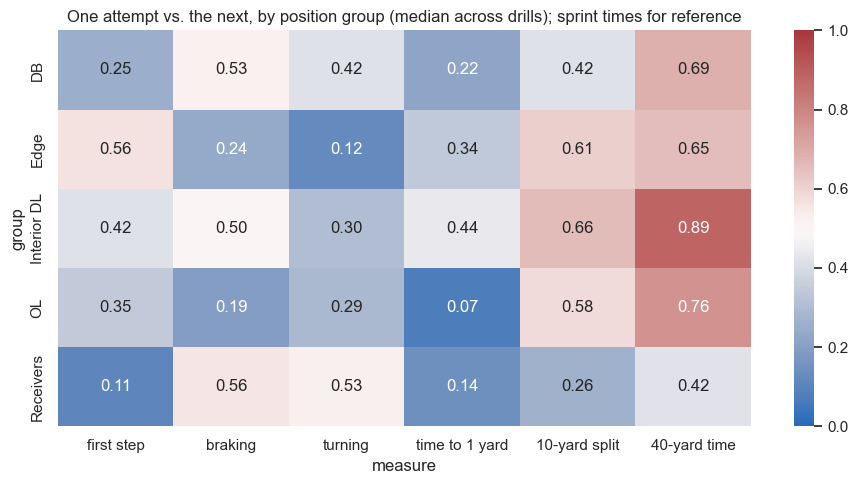

In [5]:
# 2b. Reliability of every drill, by position group (attempt 1 vs 2), with the 40 in the same group as a benchmark
def pair_table(df, m):
    w = df.pivot_table(index="nfl_id", columns="attempt", values=m).dropna()
    return w[[1, 2]] if {1, 2} <= set(w.columns) else pd.DataFrame(columns=[1, 2])


def rel_ci(w, n_boot=N_BOOT):
    r = w[1].corr(w[2], method="spearman")
    boots = [w.iloc[i][1].corr(w.iloc[i][2], method="spearman") for i in (rng.integers(0, len(w), len(w)) for _ in range(n_boot))]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return r, lo, hi


two = ATT[ATT.attempt.isin([1, 2]) & (ATT.group != "Other")]
rows = []
for (grp, drill), g in two.groupby(["group", "drill_name"]):
    for m in bc.MEAS:
        w = pair_table(g, m)
        if len(w) >= 20:
            r, lo, hi = rel_ci(w)
            rows.append(dict(group=grp, drill=drill, position_drill=not bool(g.standard_drill.iloc[0]), measure=m,
                             pairs=len(w), r=r, r_lo=lo, r_hi=hi, reps_for_0_8=bc.reps_for(r), reps_worst=bc.reps_for(lo)))
    if "FORTY" in drill:
        for m, name in [("time_40yd", "40-yard time"), ("time_10yd", "10-yard split")]:
            w = pair_table(g, m)
            if len(w) >= 15:
                r, lo, hi = rel_ci(w)
                rows.append(dict(group=grp, drill=drill, position_drill=False, measure=name, pairs=len(w), r=r,
                                 r_lo=lo, r_hi=hi, reps_for_0_8=bc.reps_for(r), reps_worst=bc.reps_for(lo)))
REL = save(pd.DataFrame(rows), "S2b_reliability_by_drill")
mv = REL[REL.measure.isin(bc.MEAS)]
S2b = (mv.groupby(["group", "position_drill"])
         .agg(drill_measures=("r", "size"), median_r=("r", "median"),
              median_reps=("reps_for_0_8", lambda x: np.median(np.clip(x, 0, 200))),
              share_needing_5plus=("reps_for_0_8", lambda x: (x >= 5).mean())).reset_index())
S2b = S2b.merge(REL[REL.measure == "40-yard time"][["group", "r"]].rename(columns={"r": "forty_r_same_group"}), on="group", how="left")
display(save(S2b, "S2b_reliability_summary").round(2))

piv = mv.groupby(["group", "measure"]).r.median().unstack("measure").rename(columns=bc.MEAS_NAME)
piv = piv.join(REL[REL.measure.isin(["40-yard time", "10-yard split"])].groupby(["group", "measure"]).r.median().unstack("measure"))
plt.figure(figsize=(9.5, 0.6 * len(piv) + 2))
sns.heatmap(piv, annot=True, fmt=".2f", cmap="vlag", center=0.5, vmin=0, vmax=1)
plt.title("One attempt vs. the next, by position group (median across drills); sprint times for reference")
savefig("S2b_reliability_heatmap")

In [6]:
# 2c. Averaging across the drills a player already runs (split-half reliability of the cross-drill average)
def split_half(d, m, n_splits=50):
    d = d[["nfl_id", "drill_name", m]].dropna()
    d = d[d.groupby("nfl_id")[m].transform("size") >= 2]
    if d.nfl_id.nunique() < 15:
        return np.nan, d.nfl_id.nunique()
    rs = []
    for s in range(n_splits):
        r_ = np.random.default_rng(s)
        d = d.assign(half=d.groupby("nfl_id")[m].transform(lambda x: r_.permutation(len(x)) % 2))
        h = d.groupby(["nfl_id", "half"])[m].mean().unstack().dropna()
        rs.append(h[0].corr(h[1], method="spearman"))
    r = float(np.mean(rs))
    return (2 * r / (1 + r) if r > 0 else np.nan), d.nfl_id.nunique()


first = P._first_z if "group" in P._first_z.columns else P._first_z.merge(ATT[["nfl_id", "group"]].drop_duplicates(), on="nfl_id", how="left")
rows = []
for grp, g in first[first.group != "Other"].groupby("group"):
    for m in ["max_decel", "max_turn", "first_step", "retention"]:
        rel, n = split_half(g, m)
        rows.append(dict(group=grp, measure=bc.MEAS_NAME[m], players=n, cross_drill_reliability=rel))
S2c = save(pd.DataFrame(rows), "S2c_cross_drill")
display(S2c.pivot(index="group", columns="measure", values="cross_drill_reliability").round(2))

measure,braking,first step,speed kept,turning
group,,,,
DB,0.19,0.58,NaN,NaN
Edge,0.12,0.28,0.44,0.26
Interior DL,0.31,0.01,NaN,NaN
OL,0.25,0.28,NaN,0.27
Receivers,0.83,0.79,0.11,0.82


In [7]:
# 2d. Left/right: does a run to one side describe the other?
fa = ATT[ATT.attempt == ATT.groupby(["nfl_id", "drill_name"]).attempt.transform("min")].copy()
fa["base"] = fa.drill_name.str.replace(r"_(LEFT|RIGHT)$", "", regex=True)
fa["side"] = fa.drill_name.str.extract(r"_(LEFT|RIGHT)$")[0]
rows = []
for base, g in fa.dropna(subset=["side"]).groupby("base"):
    for m in bc.MEAS:
        w = g.pivot_table(index="nfl_id", columns="side", values=m).dropna()
        if {"LEFT", "RIGHT"} <= set(w.columns) and len(w) >= 10:
            asym = (w.LEFT - w.RIGHT).abs() / ((w.LEFT.abs() + w.RIGHT.abs()) / 2)
            rows.append(dict(drill=base, measure=bc.MEAS_NAME[m], players=len(w),
                             left_vs_right_r=w.LEFT.corr(w.RIGHT, method="spearman"), median_asymmetry_pct=100 * asym.median()))
S2d = save(pd.DataFrame(rows), "S2d_left_right")
display(S2d.round(2) if len(S2d) else "No drill with both sides and 10+ players.")

,drill,measure,players,left_vs_right_r,median_asymmetry_pct
0,POST_CORNER_ROUTE,first step,65,0.25,5.01
1,POST_CORNER_ROUTE,time to 1 yard,65,-0.06,15.38
2,POST_CORNER_ROUTE,braking,65,-0.09,54.80
3,POST_CORNER_ROUTE,turning,65,-0.35,33.87


In [8]:
# 2e. Do Combine measures match how players move in games? Best rank correlation between any Combine result (or any
#     tracked drill measure) and each game measure, against what chance alone produces given how many were tried.
GAME_MEAS = {"cutting": ["turn_rate", "retention", "top_speed"], "burst": ["get_off", "first_step", "stop_power"]}
drill_wide = P._first_z.pivot_table(index="nfl_id", columns="drill_name", values=["max_decel", "max_turn", "first_step", "retention"])
drill_wide.columns = [f"{d}|{bc.MEAS_NAME[m]}" for m, d in drill_wide.columns]


def max_abs_rho(X, y, min_n=15):
    best = 0.0
    for c in X.columns:
        ok = X[c].notna() & y.notna()
        if ok.sum() >= min_n:
            r = stats.spearmanr(X.loc[ok, c], y[ok]).correlation
            if np.isfinite(r):
                best = max(best, abs(r))
    return best


rows = []
for key in FAMILY_KEYS:
    F = P.family(key)
    pt = F["gl"].groupby("nflId")[GAME_MEAS[F["spec"]["kind"]]].median()
    pt.index = pt.index.astype(int)
    res = RK.set_index("nfl_id").reindex(pt.index)[TIMED]
    drl = drill_wide.reindex(pt.index)
    drl = drl.loc[:, drl.notna().sum() >= 15]
    if res.notna().sum().max() < 15:
        rows.append(dict(group=GROUP_OF[key], note="no overlap between game and Combine players")); continue
    for gm in pt.columns:
        y = pt[gm]
        obs_r, obs_d = max_abs_rho(res, y), max_abs_rho(drl, y)
        null_r, null_d = [], []
        for _ in range(N_PERM):
            ys = y.copy(); ok = ys.notna(); ys[ok] = rng.permutation(ys[ok].to_numpy())
            null_r.append(max_abs_rho(res, ys)); null_d.append(max_abs_rho(drl, ys))
        rows.append(dict(group=GROUP_OF[key], game_measure=gm, players=int(y.notna().sum()),
                         results_best_rho=obs_r, results_chance=np.median(null_r), results_p=np.mean(np.array(null_r) >= obs_r),
                         drills_best_rho=obs_d, drills_chance=np.median(null_d), drills_p=np.mean(np.array(null_d) >= obs_d)))
S2e = save(pd.DataFrame(rows), "S2e_combine_vs_game")
display(S2e.round(3))

,group,game_measure,players,results_best_rho,results_chance,results_p,drills_best_rho,drills_chance,drills_p
0,DB,turn_rate,88,0.357,0.273,0.245,0.418,0.385,0.395
1,DB,retention,87,0.219,0.272,0.740,0.574,0.400,0.080
2,DB,top_speed,88,0.314,0.287,0.405,0.245,0.402,0.970
3,Receivers,turn_rate,111,0.184,0.216,0.620,0.475,0.495,0.595
4,Receivers,retention,101,0.420,0.219,0.045,0.447,0.515,0.775
5,Receivers,top_speed,111,0.760,0.225,0.000,0.423,0.478,0.745
6,OL,get_off,89,0.304,0.219,0.175,0.260,0.299,0.775
7,OL,first_step,89,0.277,0.221,0.235,0.275,0.295,0.615
8,OL,stop_power,89,0.225,0.232,0.525,0.215,0.298,0.940
9,Edge,get_off,56,0.629,0.286,0.005,0.671,0.502,0.065


## Step 3. Where injury risk is visible: an in-season model from game tracking

For every player-week in each position group, the model sees only what happened **before** that week:

| Feature | Meaning |
|---|---|
| `load_m2`, `load_m1` | Load two games ago and last game, vs. the player's own baseline (cuts per play for DBs and receivers; effort per rep for linemen) |
| `resp_drop` | Drop in the response measure from two games ago to last game (turn rate for DBs and receivers; first step for linemen) |
| `top_m1`, `top_trend` | Top speed last game vs. baseline, and its trend across the season so far |
| `plays_m1`, `games_so_far` | Usage last game and games played (the baseline model uses only these) |

The outcome is an injury onset that week. Evaluation is **leave-one-season-out**: the model is trained on two seasons and scored on the third, so every prediction is for a season it never saw. (With a single season, such as the synthetic demo data, it falls back to 5-fold cross-validation grouped by player.) A permutation test (labels shuffled within season) shows what AUC chance alone produces. The DB load-then-decline signature is also scored as a simple rule (relative risk when the flag is on).

**Strength:** pre-specified features and validation, recorded before running; still few injuries per group, so read the intervals.

In [9]:
BASE_F = ["plays_m1", "games_so_far"]
FULL_F = BASE_F + ["load_m2", "load_m1", "resp_drop", "top_m1", "top_trend"]


def risk_rows(F, gl=None):
    gl = F["gl"] if gl is None else gl
    load_col, resp_col = bc.SIGNATURE[F["spec"]["kind"]]
    onset = {(r.season, int(r.nflId)): r.onset_week for r in F["inj"].itertuples()}
    other = {(r.season, int(r.nflId)): r.onset_week for r in F["onsets"].dropna(subset=["nflId"]).itertuples()}
    rows = []
    for (nid, season), g in gl.groupby(["nflId", "season"]):
        g = g.sort_values("week")
        on = onset.get((season, int(nid)))
        stop = on if on is not None else (other[(season, int(nid))] - 1 if (season, int(nid)) in other else 99)
        cands = sorted(set(g.week.tolist() + ([on] if on is not None else [])))
        for w in cands:
            if w > stop:
                break
            prev = g[g.week < w]
            if len(prev) < 4:
                continue
            base = prev.iloc[:-2]
            bl, br, bt = base[load_col].median(), base[resp_col].median(), base.top_speed.median()
            if not (bl > 0 and br > 0 and bt > 0):
                continue
            m2, m1 = prev.iloc[-2], prev.iloc[-1]
            v = (prev.top_speed / prev.top_speed.median()).to_numpy()
            rows.append(dict(nflId=nid, season=season, week=w, label=int(on is not None and w == on),
                             load_m2=m2[load_col] / bl, load_m1=m1[load_col] / bl, resp_drop=(m2[resp_col] - m1[resp_col]) / br,
                             top_m1=m1.top_speed / bt, top_trend=np.polyfit(np.arange(len(v)), v, 1)[0],
                             plays_m1=m1.n_plays / prev.n_plays.median(), games_so_far=len(prev)))
    R = pd.DataFrame(rows)
    if len(R):
        R["signature"] = ((R.load_m2 > bc.LOAD_THR) & (R.resp_drop > bc.DROP_THR)).astype(int)
    return R


def risk_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000))


def loso_auc(R, feats, labels=None):
    """Held-out AUC: leave one season out (falls back to 5-fold grouped by player if there is only one season)."""
    y = R.label if labels is None else labels
    preds = pd.Series(np.nan, index=R.index)
    seasons = sorted(R.season.unique())
    if len(seasons) >= 2:
        splits = [(R.season != s, R.season == s) for s in seasons]
    else:
        from sklearn.model_selection import GroupKFold
        splits = []
        for tr_i, te_i in GroupKFold(n_splits=5).split(R, y, R.nflId):
            tr = pd.Series(False, index=R.index); tr.iloc[tr_i] = True
            splits.append((tr, ~tr))
    for tr, te in splits:
        if y[tr].sum() < 2 or y[te].sum() < 1:
            continue
        m = risk_model().fit(R.loc[tr, feats], y[tr])
        preds[te] = m.predict_proba(R.loc[te, feats])[:, 1]
    ok = preds.notna()
    return roc_auc_score(y[ok], preds[ok]) if ok.sum() and y[ok].nunique() == 2 else np.nan


RISK, rows = {}, []
for key in FAMILY_KEYS:
    F = P.family(key)
    R = risk_rows(F)
    RISK[key] = R
    if len(R) == 0 or R.label.sum() < 3:
        rows.append(dict(group=GROUP_OF[key], player_weeks=len(R), injuries=int(R.label.sum()) if len(R) else 0,
                         note="too few injuries")); continue
    auc_b, auc_f = loso_auc(R, BASE_F), loso_auc(R, FULL_F)
    null = []
    for _ in range(N_PERM):
        lab = R.groupby("season").label.transform(lambda x: pd.Series(rng.permutation(x.to_numpy()), index=x.index))
        null.append(loso_auc(R, FULL_F, lab))
    null = np.array([v for v in null if np.isfinite(v)])
    f1, f0 = R[R.signature == 1], R[R.signature == 0]
    rr = (f1.label.mean() / f0.label.mean()) if f0.label.mean() > 0 and len(f1) else np.nan
    _, p_sig = stats.fisher_exact([[f1.label.sum(), len(f1) - f1.label.sum()], [f0.label.sum(), len(f0) - f0.label.sum()]])
    rows.append(dict(group=GROUP_OF[key], player_weeks=len(R), injuries=int(R.label.sum()),
                     auc_usage_only=auc_b, auc_with_tracking=auc_f, auc_chance_median=np.median(null) if len(null) else np.nan,
                     perm_p=np.mean(null >= auc_f) if len(null) else np.nan,
                     signature_flag_share=R.signature.mean(), signature_relative_risk=rr, signature_p=p_sig))
S3 = save(pd.DataFrame(rows), "S3_in_season_model")
display(S3.round(3))

,group,player_weeks,injuries,auc_usage_only,auc_with_tracking,auc_chance_median,perm_p,signature_flag_share,signature_relative_risk,signature_p
0,DB,819,28,0.553,0.585,0.504,0.105,0.243,2.337,0.025
1,Receivers,722,15,0.596,0.558,0.489,0.255,0.206,0.961,1.000
2,OL,844,18,0.657,0.559,0.495,0.235,0.079,0.000,0.388
3,Edge,749,6,0.457,0.699,0.478,0.050,0.081,0.000,1.000
4,Interior DL,404,7,0.473,0.769,0.476,0.030,0.124,0.000,0.604


In [10]:
# 3b. What the DB model leans on (fit on all seasons; standardized coefficients), and the DB matched-control signature with placebo onsets
Rdb = RISK.get("db")
if Rdb is not None and len(Rdb) and Rdb.label.sum() >= 3:
    m = risk_model().fit(Rdb[FULL_F], Rdb.label)
    coefs = pd.DataFrame(dict(feature=FULL_F, standardized_coef=m.named_steps["logisticregression"].coef_[0]))
    display(save(coefs.sort_values("standardized_coef"), "S3b_db_coefficients").round(3))

DBF = P.family("db")
subj = bc.match_controls(DBF)
load_col, resp_col = bc.SIGNATURE["cutting"]
rows = []
for shift in [0, 3, 5, 7]:
    for grp in ["injured", "control"]:
        vals = [bc.signature_at(DBF["gl"], s.nflId, s.season, s.onset_week - shift, load_col, resp_col)
                for s in subj[subj.group == grp].itertuples()]
        vals = [v for v in vals if v is not None]
        rows.append(dict(weeks_before_onset=shift, group=grp, n=len(vals), signature_rate=np.mean(vals) if vals else np.nan))
S3c = pd.DataFrame(rows).pivot(index="weeks_before_onset", columns="group", values=["signature_rate", "n"])
S3c.columns = [f"{v}_{g}" for v, g in S3c.columns]
S3c = save(S3c.reset_index(), "S3c_db_placebo")
display(S3c.round(3))

,feature,standardized_coef
0,plays_m1,-0.386
5,top_m1,-0.277
2,load_m2,-0.042
3,load_m1,0.016
6,top_trend,0.090
1,games_so_far,0.295
4,resp_drop,0.418


,weeks_before_onset,signature_rate_control,signature_rate_injured,n_control,n_injured
0,0,0.200,0.429,60.0,28.0
1,3,0.240,0.316,50.0,19.0
2,5,0.109,0.222,46.0,18.0
3,7,0.325,0.200,40.0,15.0


## Step 4. More reps → better measurement → better injury prediction

Three pieces, from most direct to most theoretical:

- **4a. More reps make measurement more reliable, tested in game data.** In games, players have hundreds of reps per season, so the Spearman-Brown projection behind "8–10 reps" can be checked directly: average a measure over *k* random plays, compare with a different set of *k* plays, and see whether reliability climbs the way the formula predicts.
- **4b. More reps make injury prediction better, tested in game data.** Rebuild the Step 3 model using only *m* plays per game (2, 4, 8, 16, or all) and see whether held-out AUC rises with *m*.
- **4c. The theory linking the two:** for an injury effect of a given size, how much prediction (AUC) and how many players are needed at each number of reps.

,group,measure,reps,player_seasons,observed,projected_from_1
0,DB,turning,1,162,-0.010,-0.010
1,DB,turning,2,158,0.028,-0.020
2,DB,turning,4,158,0.090,-0.041
3,DB,turning,8,152,0.090,-0.086
4,DB,turning,16,141,0.250,-0.188
...,...,...,...,...,...,...
94,Interior DL,get-off,2,63,0.110,0.126
95,Interior DL,get-off,4,63,0.212,0.224
96,Interior DL,get-off,8,60,0.307,0.366
97,Interior DL,get-off,16,59,0.504,0.536


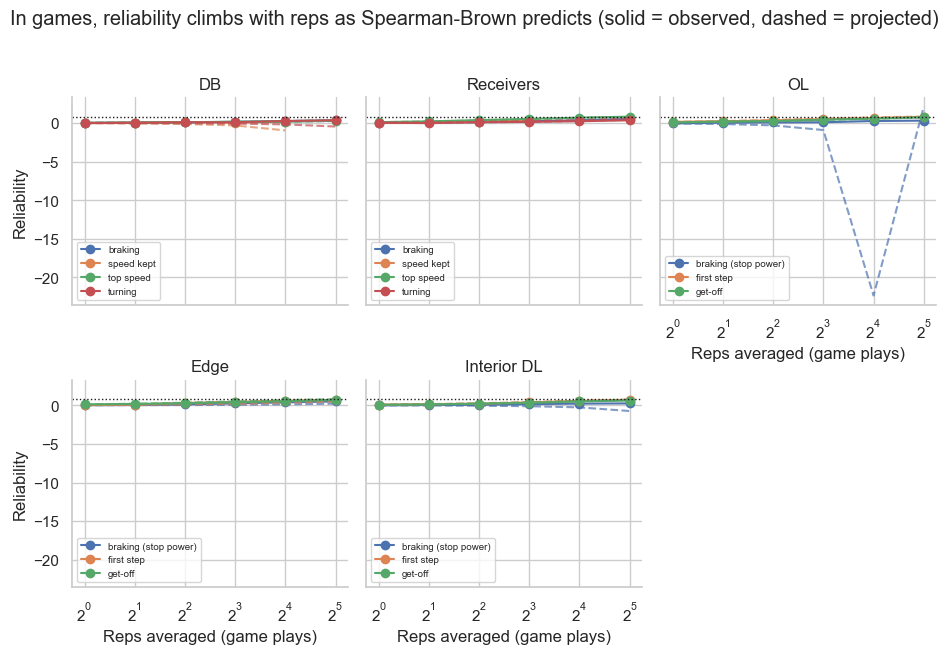

In [11]:
# 4a. Observed reliability of a k-rep average in game data vs. the Spearman-Brown projection from 1 rep
REP_MEAS = {"cutting": {"max_turn": "turning", "max_decel": "braking", "max_s": "top speed", "retention": "speed kept"},
            "burst": {"first_step": "first step", "stop_power": "braking (stop power)", "get_off": "get-off"}}
KS = [1, 2, 4, 8, 16, 32]
rows = []
for key in FAMILY_KEYS:
    F = P.family(key)
    reps = F["reps"].merge(F["T"]["games"][["gameId", "season"]], on="gameId")
    for m, name in REP_MEAS[F["spec"]["kind"]].items():
        d = reps[["nflId", "season", m]].dropna()
        r1 = None
        for k in KS:
            vals = []
            for rep_i in range(10):
                d = d.assign(rnd=np.random.default_rng(rep_i).random(len(d)))
                d["rk"] = d.groupby(["nflId", "season"]).rnd.rank(method="first")
                cnt = d.groupby(["nflId", "season"]).size()
                keep = cnt[cnt >= 2 * k].index
                if len(keep) < 20:
                    break
                a = d[d.rk <= k].groupby(["nflId", "season"])[m].mean().reindex(keep)
                b = d[(d.rk > k) & (d.rk <= 2 * k)].groupby(["nflId", "season"])[m].mean().reindex(keep)
                vals.append(a.corr(b, method="spearman"))
            if not vals:
                continue
            r = float(np.mean(vals))
            r1 = r if k == 1 else r1
            rows.append(dict(group=GROUP_OF[key], measure=name, reps=k, player_seasons=len(keep), observed=r,
                             projected_from_1=bc.spearman_brown(r1, k) if r1 is not None else np.nan))
S4a = save(pd.DataFrame(rows), "S4a_game_reps_reliability")
display(S4a.round(3))

if len(S4a):
    g = sns.FacetGrid(S4a, col="group", col_wrap=3, height=3.2, sharey=True)
    for ax, (grp, d) in zip(g.axes.flat, S4a.groupby("group", sort=False)):
        for meas, dm in d.groupby("measure"):
            l, = ax.plot(dm.reps, dm.observed, marker="o", label=meas)
            ax.plot(dm.reps, dm.projected_from_1, ls="--", color=l.get_color(), alpha=0.7)
        ax.axhline(0.8, color="k", ls=":", lw=1); ax.set_xscale("log", base=2); ax.set_title(grp); ax.legend(fontsize=7)
    g.set_axis_labels("Reps averaged (game plays)", "Reliability")
    g.fig.suptitle("In games, reliability climbs with reps as Spearman-Brown predicts (solid = observed, dashed = projected)", y=1.02)
    savefig("S4a_game_reps_reliability")

In [12]:
# 4b. Injury prediction vs. plays per game used to build the game measures (held-out AUC, Step 3 model)
M_PLAYS = [2, 4, 8, 16, None]
rows = []
for key in FAMILY_KEYS:
    F = P.family(key)
    if key not in RISK or len(RISK[key]) == 0 or RISK[key].label.sum() < 3:
        continue
    valid = F["gl"][["nflId", "gameId"]]
    for mp in M_PLAYS:
        aucs = []
        for seed in ([0] if mp is None else [0, 1, 2]):
            reps = F["reps"]
            if mp is not None:
                reps = (reps.assign(rnd=np.random.default_rng(seed).random(len(reps)))
                            .sort_values("rnd").groupby(["nflId", "gameId"]).head(mp))
            glm = bc.game_level(reps, F["spec"]["kind"]).merge(valid, on=["nflId", "gameId"])
            glm = glm.merge(F["T"]["games"][["gameId", "season", "week"]], on="gameId")
            Rm = risk_rows(F, glm)
            if len(Rm) and Rm.label.sum() >= 3:
                aucs.append(loso_auc(Rm, FULL_F))
        rows.append(dict(group=GROUP_OF[key], plays_per_game="all" if mp is None else mp,
                         held_out_auc=np.nanmean(aucs) if aucs else np.nan))
S4b = save(pd.DataFrame(rows), "S4b_auc_vs_plays")
display(S4b.pivot(index="plays_per_game", columns="group", values="held_out_auc").round(3) if len(S4b) else "not enough injuries")

group,DB,Edge,Interior DL,OL,Receivers
plays_per_game,,,,,
2,NaN,0.584,0.646,0.512,NaN
4,0.534,0.465,0.490,0.461,NaN
8,0.559,0.505,0.541,0.522,0.350
16,0.441,0.599,0.727,0.546,0.509
all,0.585,0.699,0.769,0.559,0.558


,true_effect_d,drill,single_rep_r,reps,reliability,expected_auc,players_needed
10,0.5,typical DB position drill,0.52,1,0.524,0.601,375
11,0.5,typical DB position drill,0.52,2,0.687,0.615,286
12,0.5,typical DB position drill,0.52,3,0.767,0.622,256
13,0.5,typical DB position drill,0.52,5,0.846,0.627,232
14,0.5,typical DB position drill,0.52,10,0.917,0.633,215
15,0.5,best DB position drill,0.69,1,0.690,0.615,285
16,0.5,best DB position drill,0.69,2,0.816,0.625,241
17,0.5,best DB position drill,0.69,3,0.870,0.629,226
18,0.5,best DB position drill,0.69,5,0.917,0.633,214
19,0.5,best DB position drill,0.69,10,0.957,0.635,206


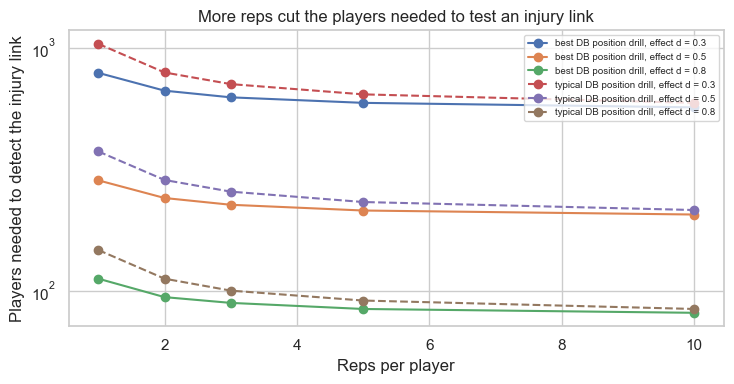

In [13]:
# 4c. Theory: prediction and sample size vs. reps, for an injury effect of a given size
#     Observed effect = true effect x sqrt(reliability). AUC = Phi(d_obs / sqrt(2)) for a standardized difference d.
db_pos = REL[(REL.group == "DB") & REL.position_drill & REL.measure.isin(["max_turn", "max_decel"])]
r_drill = float(db_pos.r.max()) if len(db_pos) else 0.65
r_generic = float(db_pos.r.median()) if len(db_pos) else 0.3
rows = []
for d in [0.3, 0.5, 0.8]:
    for label, r1 in [("typical DB position drill", r_generic), ("best DB position drill", r_drill)]:
        for k in [1, 2, 3, 5, 10]:
            rel = bc.spearman_brown(r1, k)
            d_obs = d * np.sqrt(rel)
            n = (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) ** 2 * (1 / 0.2 + 1 / 0.8) / d_obs ** 2
            rows.append(dict(true_effect_d=d, drill=label, single_rep_r=round(r1, 2), reps=k, reliability=rel,
                             expected_auc=stats.norm.cdf(d_obs / np.sqrt(2)), players_needed=int(np.ceil(n))))
S4c = save(pd.DataFrame(rows), "S4c_theory")
display(S4c[S4c.true_effect_d == 0.5].round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
for (label, d), g in S4c.groupby(["drill", "true_effect_d"]):
    ax.plot(g.reps, g.players_needed, marker="o", ls="-" if label.startswith("best") else "--",
            label=f"{label}, effect d = {d}")
ax.set_yscale("log"); ax.set_xlabel("Reps per player"); ax.set_ylabel("Players needed to detect the injury link")
ax.set_title("More reps cut the players needed to test an injury link"); ax.legend(fontsize=7)
savefig("S4c_players_needed")

## Step 5. A Combine drill for each position group

For each group's key traits (chosen from the movements that load the body in that position), the existing **position drill** with the most repeatable single attempt, how many tracked reps it needs to reach 0.8 (point estimate and the pessimistic end of the interval), how many attempts players get today, and the strength of that group's in-season tracking signal from Step 3. Where no existing drill measures a trait reliably, the table says a new drill is needed.

| Group | Key traits | Why |
|---|---|---|
| DB | turning, braking, speed kept | The DB in-game pattern is about turning after heavy cutting |
| Receivers | braking, turning | Deceleration into route breaks |
| OL | braking, first step | Stopping and redirecting in pass protection; get-off |
| Edge | first step, turning | Get-off and bend |
| Interior DL | first step, braking | Get-off into contact |

In [14]:
KEY_TRAITS = {"DB": ["max_turn", "max_decel", "retention"], "Receivers": ["max_decel", "max_turn"],
              "OL": ["max_decel", "first_step"], "Edge": ["first_step", "max_turn"], "Interior DL": ["first_step", "max_decel"]}
attempts_now = ATT.groupby(["drill_name", "nfl_id"]).attempt.max().groupby("drill_name").median()
s3 = S3.set_index("group") if len(S3) else pd.DataFrame()
rows = []
for grp, traits in KEY_TRAITS.items():
    ev = ""
    if grp in s3.index and "auc_with_tracking" in s3.columns and pd.notna(s3.loc[grp].get("auc_with_tracking", np.nan)):
        ev = (f"in-season AUC {s3.loc[grp, 'auc_with_tracking']:.2f} vs. {s3.loc[grp, 'auc_usage_only']:.2f} usage-only "
              f"(permutation p = {s3.loc[grp, 'perm_p']:.2f})")
    for t in traits:
        c = REL[(REL.group == grp) & REL.position_drill & (REL.measure == t)].sort_values("r", ascending=False)
        if len(c) == 0 or c.r.iloc[0] < 0.2:
            rows.append(dict(group=grp, trait=bc.MEAS_NAME[t], best_existing_drill="none measures it reliably",
                             recommendation="new drill needed: repeated reps with a hard break at speed",
                             in_season_evidence=ev)); continue
        b = c.iloc[0]
        reps = int(np.clip(np.ceil(b.reps_for_0_8), 2, 15))
        reps_hi = int(np.clip(np.ceil(b.reps_worst), reps, 30)) if np.isfinite(b.reps_worst) else None
        sides = " to both sides" if t in ("max_turn", "max_decel", "retention") else ""
        rows.append(dict(group=grp, trait=bc.MEAS_NAME[t], best_existing_drill=b.drill, single_attempt_r=b.r,
                         r_interval=f"{b.r_lo:.2f}–{b.r_hi:.2f}", players=b.pairs,
                         attempts_today=attempts_now.get(b.drill, np.nan),
                         reps_for_0_8=f"{reps}" + (f" (up to {reps_hi})" if reps_hi and reps_hi > reps else ""),
                         recommendation=f"run {b.drill} for {reps}–{max(reps + 2, reps_hi or reps)} tracked reps{sides}; score the average and the change from first to last reps",
                         in_season_evidence=ev))
S5 = save(pd.DataFrame(rows), "S5_drill_recommendations")
display(S5)

,group,trait,best_existing_drill,single_attempt_r,r_interval,players,attempts_today,reps_for_0_8,recommendation,in_season_evidence
0,DB,turning,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,0.631388,0.42–0.76,71.0,2.0,3 (up to 6),run BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTI...,in-season AUC 0.59 vs. 0.55 usage-only (permut...
1,DB,braking,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,0.689616,0.55–0.79,71.0,2.0,2 (up to 4),run BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTI...,in-season AUC 0.59 vs. 0.55 usage-only (permut...
2,DB,speed kept,none measures it reliably,NaN,NaN,NaN,NaN,NaN,new drill needed: repeated reps with a hard br...,in-season AUC 0.59 vs. 0.55 usage-only (permut...
3,Receivers,braking,GAUNTLET_DRILL,0.624416,0.46–0.75,83.0,2.0,3 (up to 5),run GAUNTLET_DRILL for 3–5 tracked reps to bot...,in-season AUC 0.56 vs. 0.60 usage-only (permut...
4,Receivers,turning,GAUNTLET_DRILL,0.663049,0.51–0.78,83.0,2.0,3 (up to 4),run GAUNTLET_DRILL for 3–5 tracked reps to bot...,in-season AUC 0.56 vs. 0.60 usage-only (permut...
5,OL,braking,none measures it reliably,NaN,NaN,NaN,NaN,NaN,new drill needed: repeated reps with a hard br...,in-season AUC 0.56 vs. 0.66 usage-only (permut...
6,OL,first step,none measures it reliably,NaN,NaN,NaN,NaN,NaN,new drill needed: repeated reps with a hard br...,in-season AUC 0.56 vs. 0.66 usage-only (permut...
7,Edge,first step,SHORT_ZONE_BREAKS,0.564505,0.24–0.76,33.0,3.0,4 (up to 13),run SHORT_ZONE_BREAKS for 4–13 tracked reps; s...,in-season AUC 0.70 vs. 0.46 usage-only (permut...
8,Edge,turning,none measures it reliably,NaN,NaN,NaN,NaN,NaN,new drill needed: repeated reps with a hard br...,in-season AUC 0.70 vs. 0.46 usage-only (permut...
9,Interior DL,first step,none measures it reliably,NaN,NaN,NaN,NaN,NaN,new drill needed: repeated reps with a hard br...,in-season AUC 0.77 vs. 0.47 usage-only (permut...


## What to send back
Run the cell below and paste everything it prints. Also useful (optional): the figures in `outputs/main/` (`S2b_reliability_heatmap.png`, `S4a_game_reps_reliability.png`, `S4c_players_needed.png`, `S1_injury_by_round.png`).

In [15]:
def show(title, df, cols=None):
    print(f"\n=== {title} ===")
    if df is None or len(df) == 0:
        print("(none)"); return
    print((df[cols] if cols else df).round(3).to_string(index=False))


show("Step 1. Burden", S1)
show("Step 1. By draft round", by_round)
if "S1c_sum" in globals():
    show("Step 1. Follow-up (descriptive)", S1c_sum)
show("Step 2a. Combine vs rookie injury: summary", summary_2a)
show("Step 2a. Cross-validated AUC", S2a_auc)
show("Step 2b. Reliability summary", S2b)
show("Step 2b. Most and least repeatable position-drill measures",
     pd.concat([mv[mv.position_drill].nlargest(6, "r"), mv[mv.position_drill].nsmallest(6, "r")]),
     ["group", "drill", "measure", "pairs", "r", "r_lo", "r_hi", "reps_for_0_8"])
show("Step 2c. Cross-drill averages", S2c)
show("Step 2d. Left/right", S2d)
show("Step 2e. Combine vs game movement", S2e)
show("Step 3. In-season model", S3)
show("Step 3c. DB signature with placebo onsets", S3c)
show("Step 4a. Game reps reliability", S4a)
show("Step 4b. AUC vs plays per game", S4b)
show("Step 4c. Theory (effect d = 0.5)", S4c[S4c.true_effect_d == 0.5])
show("Step 5. Drill recommendations", S5)
print(f"\nAll tables and figures saved to {OUT.resolve()}")


=== Step 1. Burden ===
                                             measure   value
Rookies (all 510 drafted players, 5 position groups) 505.000
                      Share injured as rookies (all)   0.196
     Share injured among rookies who played 4+ games   0.251
              Games missed per injured rookie (mean)   3.414
            Games missed per injured rookie (median)   3.000
                    Injured rookies missing 4+ games   0.323
                   Total rookie games lost to injury 338.000

=== Step 1. By draft round ===
round_group  players  injured_share  injured_share_4plus_games  mean_games_missed_if_injured
    Round 1       38          0.211                      0.189                         4.125
 Rounds 2–3      118          0.314                      0.310                         3.730
 Rounds 4–5      118          0.212                      0.229                         3.680
 Rounds 6–7      105          0.190                      0.230                      